# 01 — Preprocessing Pipeline

Runs the full detection-bias-corrected preprocessing pipeline (Algorithms 1–8
from the paper) via the installable `pp_tgnn` package, and reproduces Figure 1.

**Prerequisites:**
```bash
pip install -e ..    # from the notebooks/ directory, installs the pp_tgnn package
```
and the two raw files placed at `../data/raw/SA02601_v6.csv` and
`../data/raw/SA02602_v5.csv` (see `../data/raw/README.md`).

For a step-by-step walkthrough of *what each algorithm does and why*, see the
inline docstrings in `src/pp_tgnn/pipeline.py` — this notebook focuses on
running the pipeline and inspecting/validating its output.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from pp_tgnn.config import PipelineConfig
from pp_tgnn.pipeline import run_pipeline
from pp_tgnn.figures import make_figure1

VIS_PATH = Path("../data/raw/SA02601_v6.csv")
FLW_PATH = Path("../data/raw/SA02602_v5.csv")
OUTDIR = Path("../data/processed")

import logging
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)-7s | %(message)s", datefmt="%H:%M:%S")


## Run the pipeline (Algorithms 1–8)

In [2]:
cfg = PipelineConfig()  # default column names match the real SA02601/SA02602 schema
outputs = run_pipeline(VIS_PATH, FLW_PATH, OUTDIR, cfg=cfg)

events = outputs["events"]
train, val, test = outputs["train"], outputs["val"], outputs["test"]
events.head()


07:36:14 | INFO    | Loading raw visitation file: ../data/raw/SA02601_v6.csv


07:36:14 | INFO    | Loading raw flowering file: ../data/raw/SA02602_v5.csv


07:36:14 | INFO    | Harmonized vis=74942 rows, flw=23642 rows


07:36:14 | INFO    | Partitioned E+=61025 rows, E0=13917 rows (53 NO_INT values filled with 1)


07:36:14 | INFO    | Built 17472 replicate groups


07:36:14 | INFO    | Informative groups (K_g >= 2): 17342 / 17472 total


... (11 outputs left out)

07:36:22 | INFO    | Fraction imputed flowering: 0.245%


07:36:22 | INFO    | Detection probability p_hat: 0.150


07:36:22 | INFO    | ============================================================


,tau,date,plant_id,pollinator_id,NO_INT,confidence_posterior,confidence_flowering,c,is_imputed_flowering,PLOT_ID,YEAR,WATCH
0,0,2011-07-12,DELPNUTT,BOMBMIXT,1.0,0.933148,0.202518,0.188979,False,CPR03,2011,1.0
1,0,2011-07-12,DELPNUTT,BOMBMIXT,1.0,0.802235,0.281043,0.225463,False,CPR07,2011,1.0
2,0,2011-07-12,VIOLORBI,PLATRUFI,1.0,0.115190,0.630930,0.072677,False,CPB02,2011,1.0
3,0,2011-07-12,DELPNUTT,SYRPRIBE,1.0,0.133457,0.202518,0.027028,False,CPR03,2011,1.0
4,0,2011-07-12,LOMAMART,XYLOSPX4,3.0,0.345555,0.614352,0.212293,False,CPM01,2011,1.0


## Sanity-check against the paper's reported summary statistics (Section 1.1)

In [3]:
n_pairs = events[["plant_id", "pollinator_id"]].drop_duplicates().shape[0]
n_plants = events["plant_id"].nunique()
n_polls = events["pollinator_id"].nunique()
density = n_pairs / (n_plants * n_polls)

print(f"Positive events:       {len(events)}   (paper: 20,107)")
print(f"Distinct plants:       {n_plants}      (paper: 147)")
print(f"Distinct pollinators:  {n_polls}      (paper: 800)")
print(f"Pair density:          {100*density:.2f}%  (paper: 3.85%)")
print(f"Median edge weight c:  {events['c'].median():.3f}   (paper: 0.096)")
print(f"p_hat:                 {outputs['p_hat']:.3f}    (paper: 0.15)")
print(f"Imputed flowering:     {100*events['is_imputed_flowering'].mean():.3f}%  (paper: 0.24%)")


Positive events:       20025   (paper: 20,107)
Distinct plants:       147      (paper: 147)
Distinct pollinators:  800      (paper: 800)
Pair density:          3.85%  (paper: 3.85%)
Median edge weight c:  0.096   (paper: 0.096)
p_hat:                 0.150    (paper: 0.15)
Imputed flowering:     0.245%  (paper: 0.24%)


## Figure 1

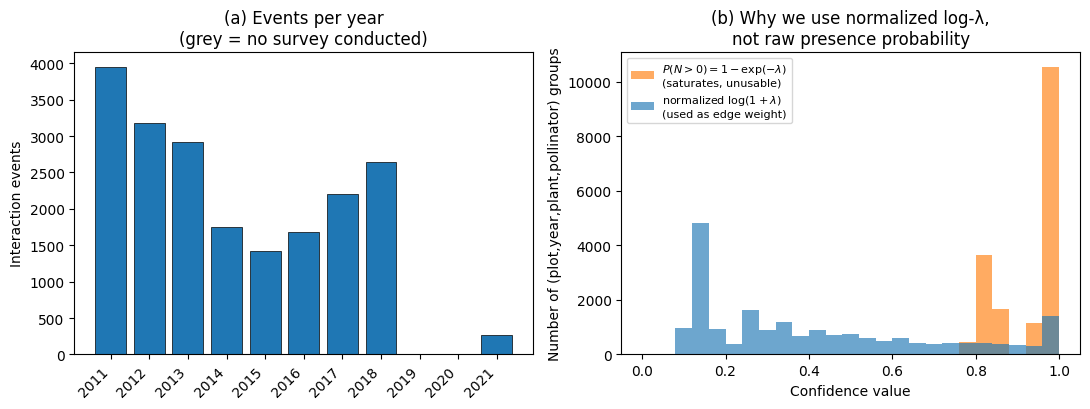

In [4]:
fig = make_figure1(events, outputs["lambda_hat"], out_path=Path("../figures/figure1.png"))
plt.show()


## Leakage check on the chronological split

In [5]:
assert train["tau"].max() <= val["tau"].min()
assert val["tau"].max() <= test["tau"].min()
print("Chronological split verified: train ≤ val ≤ test along tau. No leakage.")
print(f"train={len(train)}  val={len(val)}  test={len(test)}")


Chronological split verified: train ≤ val ≤ test along tau. No leakage.
train=16020  val=2002  test=2003
